<img src="images\Logo_UCLL_ENG_RGB.png" style="background-color:white;" />

# Data Analytics & Machine learning

Lecturers: Aimée Lynn Backiel, Lies Bollens, Fien Van de Woestijne

Academic year 2026-2027

## Lab 7: Classification

### Lecture outline

1. One large exercise covering all we have done so far in this course applied to classification.

### Recap of last lecture(s)

#### Lab 1

1. We ensured we had a valid Python installation.
2. We learnt what a virtual environment is:
   * Isolated Python executable and packages.
   * We created a virtual environment.
3. Absolute path vs relative path recap.
4. Recap of data structures in Python
5. Installed Pandas
6. Learnt how to read data
7. Learnt how to calculate mean, mode, median etc.
8. Basic exploration of the 4 variables

#### Lab 2
1. Wrapped up computing summary statistics (mean, median, mode, ...)
2. Learnt how to deal with outliers 
3. Focused on exploration of data

#### Lab 3
1. Univariate data visualization using Matplotlib
   1. Figures and axes
   2. Histograms
   3. Box plots
   4. Bar charts
2. Multivariate data visualization using Seaborn
   1. Scatter plots
   2. Small multiples
   3. Color coding

#### Lab 4
1. Intro to machine learning using scikit-learn
   1. Preprocessing
      1. One Hot encoding
      2. Scaling
      3. Outliers
   2. Regression

#### Lab 5
1. Preprocessing with scikit-learn
   1. ColumnTransformer: Apply a transformation to specific columns.
   2. Pipeline: Do several transformations after each other
2. Evaluation:
   1. Why the mean of the error is a bad idea
   2. Mean absolute error
   3. Mean squared error

### Lab 6
1. Feature engineering
   1. Binning
   2. Interactions
   3. Custom features
2. Rounding up model evaluation
   1. Cross validation
   2. Hyper parameter tuning

## Business understanding

#### Our next case: Hotel booking dataset

source: https://www.sciencedirect.com/science/article/pii/S2352340918315191

*This data article describes two datasets with hotel demand data. One of the hotels (H1) is a resort hotel and the other is a city hotel (H2). Both datasets share the same structure, with 31 variables describing the 40,060 observations of H1 and 79,330 observations of H2. Each observation represents a hotel booking. Both datasets comprehend bookings due to arrive between the 1st of July of 2015 and the 31st of August 2017, including bookings that effectively arrived and bookings that were canceled. Both hotels are located in Portugal: H1 at the resort region of Algarve and H2 at the city of Lisbon.*

The goal is to help the two hotels maximize their revenue.



|variable                       |class     |description |
|:------------------------------|:---------|:-----------|
|hotel                          |character | Hotel (H1 = Resort Hotel or H2 = City Hotel) |
|is_canceled                    |double    | Value indicating if the booking was canceled (1) or not (0) |
|lead_time                      |double    | Number of days that elapsed between the entering date of the booking into the PMS and the arrival date |
|arrival_date_year              |double    | Year of arrival date|
|arrival_date_month             |character | Month of arrival date|
|arrival_date_week_number       |double    | Week number of year for arrival date|
|arrival_date_day_of_month      |double    | Day of arrival date|
|stays_in_weekend_nights        |double    | Number of weekend nights (Saturday or Sunday) the guest stayed or booked to stay at the hotel |
|stays_in_week_nights           |double    |  Number of week nights (Monday to Friday) the guest stayed or booked to stay at the hotel|
|adults                         |double    | Number of adults|
|children                       |double    | Number of children|
|babies                         |double    |Number of babies |
|meal                           |character | Type of meal booked. Categories are presented in standard hospitality meal packages: <br> Undefined/SC – no meal package;<br>BB – Bed & Breakfast; <br> HB – Half board (breakfast and one other meal – usually dinner); <br> FB – Full board (breakfast, lunch and dinner) |
|country                        |character | Country of origin. Categories are represented in the ISO 3155–3:2013 format |
|market_segment                 |character | Market segment designation. In categories, the term “TA” means “Travel Agents” and “TO” means “Tour Operators” |
|distribution_channel           |character | Booking distribution channel. The term “TA” means “Travel Agents” and “TO” means “Tour Operators” |
|is_repeated_guest              |double    | Value indicating if the booking name was from a repeated guest (1) or not (0) |
|previous_cancellations         |double    | Number of previous bookings that were cancelled by the customer prior to the current booking |
|previous_bookings_not_canceled |double    | Number of previous bookings not cancelled by the customer prior to the current booking |
|reserved_room_type             |character | Code of room type reserved. Code is presented instead of designation for anonymity reasons |
|assigned_room_type             |character | Code for the type of room assigned to the booking. Sometimes the assigned room type differs from the reserved room type due to hotel operation reasons (e.g. overbooking) or by customer request. Code is presented instead of designation for anonymity reasons |
|booking_changes                |double    | Number of changes/amendments made to the booking from the moment the booking was entered on the PMS until the moment of check-in or cancellation|
|deposit_type                   |character | Indication on if the customer made a deposit to guarantee the booking. This variable can assume three categories:<br>No Deposit – no deposit was made;<br>Non Refund – a deposit was made in the value of the total stay cost;<br>Refundable – a deposit was made with a value under the total cost of stay. |
|agent                          |character | ID of the travel agency that made the booking |
|company                        |character | ID of the company/entity that made the booking or responsible for paying the booking. ID is presented instead of designation for anonymity reasons |
|days_in_waiting_list           |double    | Number of days the booking was in the waiting list before it was confirmed to the customer |
|customer_type                  |character | Type of booking, assuming one of four categories:<br>Contract - when the booking has an allotment or other type of contract associated to it;<br>Group – when the booking is associated to a group;<br>Transient – when the booking is not part of a group or contract, and is not associated to other transient booking;<br>Transient-party – when the booking is transient, but is associated to at least other transient booking|
|adr                            |double    | Average Daily Rate as defined by dividing the sum of all lodging transactions by the total number of staying nights |
|required_car_parking_spaces    |double    | Number of car parking spaces required by the customer |
|total_of_special_requests      |double    | Number of special requests made by the customer (e.g. twin bed or high floor)|
|reservation_status             |character | Reservation last status, assuming one of three categories:<br>Canceled – booking was canceled by the customer;<br>Check-Out – customer has checked in but already departed;<br>No-Show – customer did not check-in and did inform the hotel of the reason why |
|reservation_status_date        |double    | Date at which the last status was set. This variable can be used in conjunction with the ReservationStatus to understand when was the booking canceled or when did the customer checked-out of the hotel|





## Data understanding

#### ❓ Go back to lab 2. Read in the H1 and H2 dataset. What was the very first step when working with a dataset? Execute that one. Make sure the necessary packages are installed and imported.

In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.float_format = "{:.2f}".format

# Read datasets (adjust path to "data/H1.csv" if your CSVs are inside a data folder)
h1 = pd.read_csv("data/H1.csv")
h2 = pd.read_csv("data/H2.csv")

# Very first step from Lab 2: inspect the first few rows, columns, and structure
display(h1.head())
display(h2.head())
print("H1 shape:", h1.shape)
print("H2 shape:", h2.shape)

,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,342,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.00,0,0,Check-Out,2015-07-01
1,0,737,2015,July,27,1,0,0,2,0,...,No Deposit,NULL,NULL,0,Transient,0.00,0,0,Check-Out,2015-07-01
2,0,7,2015,July,27,1,0,1,1,0,...,No Deposit,NULL,NULL,0,Transient,75.00,0,0,Check-Out,2015-07-02
3,0,13,2015,July,27,1,0,1,1,0,...,No Deposit,304,NULL,0,Transient,75.00,0,0,Check-Out,2015-07-02
4,0,14,2015,July,27,1,0,2,2,0,...,No Deposit,240,NULL,0,Transient,98.00,0,1,Check-Out,2015-07-03


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,DepositType,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate
0,0,6,2015,July,27,1,0,2,1,0.00,...,No Deposit,6,NULL,0,Transient,0.00,0,0,Check-Out,2015-07-03
1,1,88,2015,July,27,1,0,4,2,0.00,...,No Deposit,9,NULL,0,Transient,76.50,0,1,Canceled,2015-07-01
2,1,65,2015,July,27,1,0,4,1,0.00,...,No Deposit,9,NULL,0,Transient,68.00,0,1,Canceled,2015-04-30
3,1,92,2015,July,27,1,2,4,2,0.00,...,No Deposit,9,NULL,0,Transient,76.50,0,2,Canceled,2015-06-23
4,1,100,2015,July,27,2,0,2,2,0.00,...,No Deposit,9,NULL,0,Transient,76.50,0,1,Canceled,2015-04-02


H1 shape: (40060, 31)
H2 shape: (79330, 31)


#### ❓ The next thing we need to decide on, is what we want to do with this dataset. We have many different variables and thus things we can do. What would you do with this dataset?

My Answer:
The overall business goal is to help both the resort hotel (H1) and the city hotel (H2) maximize their revenue. With these 31 variables, we can tackle several machine learning tasks:
1. **Classification (Primary goal):** Predict whether a booking will be canceled (`IsCanceled` = 1) or not (`IsCanceled` = 0) using booking characteristics such as lead time, deposit type, market segment, stay duration, and special requests. Knowing which bookings are likely to cancel lets hotels optimize overbooking strategies and deposit policies.
2. **Regression:** Predict the Average Daily Rate (`ADR`) or expected stay duration/room demand for a given period.
3. **Clustering:** Segment guests into distinct customer profiles based on party size, country, booking channel, and special requests to tailor marketing campaigns.

We can think of multiple things to do with this set:
1. Finding out who cancels reservations (classifcation)
2. Finding groups in the customers (clustering)
3. Predicting the amount of rooms to be booked on a given day (regression)
4. ...

We will focus in this lab on finding out who cancels their reservation. This means we will be **predicting a categorical value**. `isCanceled` is a number but in our dataset it should be regarded as a discrete category. This is called **classification**. When doing classification we will need slightly different machine learning models but most importantly, we will need different evaluation metrics. The full details are discussed in the theory sessions.

We still start of by doing exploring the dataset using Pandas exclusively and move on to some plots later on. The choice of which tool to use is yours. Start by combining both dataset in to one set called 'hotel_df'. Make sure to indicate which data is coming from which hotel.

In [19]:
h1["hotel"] = "Resort hotel"
h2["hotel"] = "City hotel"

hotel_df = pd.concat([h1, h2], ignore_index=True)
print("Combined shape:", hotel_df.shape)
hotel_df.head()

Combined shape: (119390, 32)


,IsCanceled,LeadTime,ArrivalDateYear,ArrivalDateMonth,ArrivalDateWeekNumber,ArrivalDateDayOfMonth,StaysInWeekendNights,StaysInWeekNights,Adults,Children,...,Agent,Company,DaysInWaitingList,CustomerType,ADR,RequiredCarParkingSpaces,TotalOfSpecialRequests,ReservationStatus,ReservationStatusDate,hotel
0,0,342,2015,July,27,1,0,0,2,0.00,...,NULL,NULL,0,Transient,0.00,0,0,Check-Out,2015-07-01,Resort hotel
1,0,737,2015,July,27,1,0,0,2,0.00,...,NULL,NULL,0,Transient,0.00,0,0,Check-Out,2015-07-01,Resort hotel
2,0,7,2015,July,27,1,0,1,1,0.00,...,NULL,NULL,0,Transient,75.00,0,0,Check-Out,2015-07-02,Resort hotel
3,0,13,2015,July,27,1,0,1,1,0.00,...,304,NULL,0,Transient,75.00,0,0,Check-Out,2015-07-02,Resort hotel
4,0,14,2015,July,27,1,0,2,2,0.00,...,240,NULL,0,Transient,98.00,0,1,Check-Out,2015-07-03,Resort hotel


### Data understanding

#### ❓ First, take a general look at the data. Are there any missing values? Are there any values that do not make sense. Make sure to handle these missing values appropriatly. Then formulate and anwser at least 3 business questions that you think are interesting. Focus on one variable at the time. Use plots as well as metrics to study these variables.
An example of a possible business question might be: "Which countries are our guests coming from?". In a later stage, you could look at the relationship between country of origin and the cancellations. Create your own code and markdown cells. Make sure to explain/document everything you do.

In [20]:
# 1. Check missing values
print("Missing values per column:")
print(hotel_df.isnull().sum()[hotel_df.isnull().sum() > 0])

# 2. Check values that do not make sense
zero_guests = hotel_df[(hotel_df["Adults"] + hotel_df["Children"].fillna(0) + hotel_df["Babies"]) == 0]
neg_adr = hotel_df[hotel_df["ADR"] < 0]
print(f"\nBookings with 0 total guests: {len(zero_guests)}")
print(f"Bookings with negative ADR: {len(neg_adr)}")

# 3. Handle missing values appropriately
hotel_df["Children"] = hotel_df["Children"].fillna(0)
hotel_df["Country"] = hotel_df["Country"].fillna("Unknown")

print("\nRemaining missing values:", hotel_df.isnull().sum().sum())

Missing values per column:
Children      4
Country     488
dtype: int64

Bookings with 0 total guests: 180
Bookings with negative ADR: 1

Remaining missing values: 0


My Answer:
### Data Cleaning Findings
- **Missing values:** `Children` has 4 missing values (imputed with `0`, assuming no children were booked) and `Country` has 488 missing values (filled with `"Unknown"` so we do not lose those bookings).
- **Anomalous values:** There are 180 bookings with 0 total guests (`Adults + Children + Babies == 0`) and 1 booking with a negative `ADR` (`-6.38`), likely caused by administrative adjustments or system entry errors.

1. Cancellation counts & proportions:
IsCanceled
0   0.63
1   0.37
Name: proportion, dtype: float64

2. LeadTime summary statistics:
count   119390.00
mean       104.01
std        106.86
min          0.00
25%         18.00
50%         69.00
75%        160.00
max        737.00
Name: LeadTime, dtype: float64

3. ADR summary statistics:
count   119390.00
mean       101.83
std         50.54
min         -6.38
25%         69.29
50%         94.58
75%        126.00
max       5400.00
Name: ADR, dtype: float64


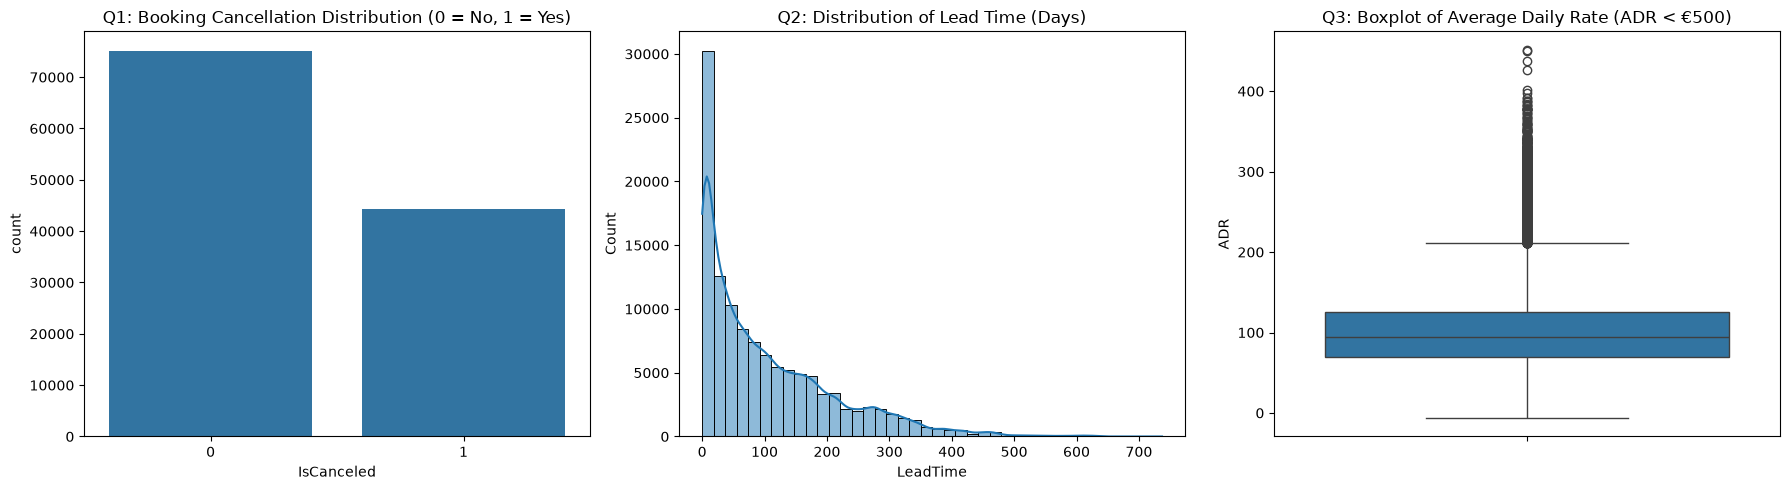

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Business Question 1: What proportion of all bookings get canceled?
print("1. Cancellation counts & proportions:")
print(hotel_df["IsCanceled"].value_counts(normalize=True).round(3))
sns.countplot(data=hotel_df, x="IsCanceled", ax=axes[0])
axes[0].set_title("Q1: Booking Cancellation Distribution (0 = No, 1 = Yes)")

# Business Question 2: How far in advance do guests book (LeadTime)?
print("\n2. LeadTime summary statistics:")
print(hotel_df["LeadTime"].describe().round(2))
sns.histplot(data=hotel_df, x="LeadTime", bins=40, kde=True, ax=axes[1])
axes[1].set_title("Q2: Distribution of Lead Time (Days)")

# Business Question 3: What is the typical Average Daily Rate (ADR)?
print("\n3. ADR summary statistics:")
print(hotel_df["ADR"].describe().round(2))
sns.boxplot(data=hotel_df[hotel_df["ADR"] < 500], y="ADR", ax=axes[2])
axes[2].set_title("Q3: Boxplot of Average Daily Rate (ADR < €500)")

plt.tight_layout()
plt.show()

My Answer:
### Univariate Business Questions & Findings
1. **What proportion of bookings are canceled?** Roughly **37.0%** of all bookings (`44,224`) are canceled, while **63.0%** (`75,166`) are not canceled.
2. **How far in advance do customers book?** `LeadTime` is heavily right-skewed: the median booking is made **69 days** in advance, while the mean is **104.01 days** (std = 106.86) due to bookings made up to 737 days ahead.
3. **How much do guests pay per night (`ADR`)?** The median nightly rate is **€94.58** and the mean is **€101.83** (IQR: €69.29–€126.00), with a few extreme high outliers up to €5,400.

#### ❓ Now, move on to a bivariate or multivariate analysis: looking at the relationship between two or more of the variables at the same time. Again, start by formulating questions and answer them. Keep in mind that we want to figure out why people cancel their holidays.

Q1: Cancellation rate by hotel:
              count  mean
hotel                    
City hotel    79330  0.42
Resort hotel  40060  0.28

Q2: Cancellation rate by DepositType:
                  count  mean
DepositType                  
No Deposit       104641  0.28
Non Refund        14587  0.99
Refundable          162  0.22

Q3: Mean LeadTime by Hotel and IsCanceled:
IsCanceled       0      1
hotel                    
City hotel   80.70 150.28
Resort hotel 78.84 128.68


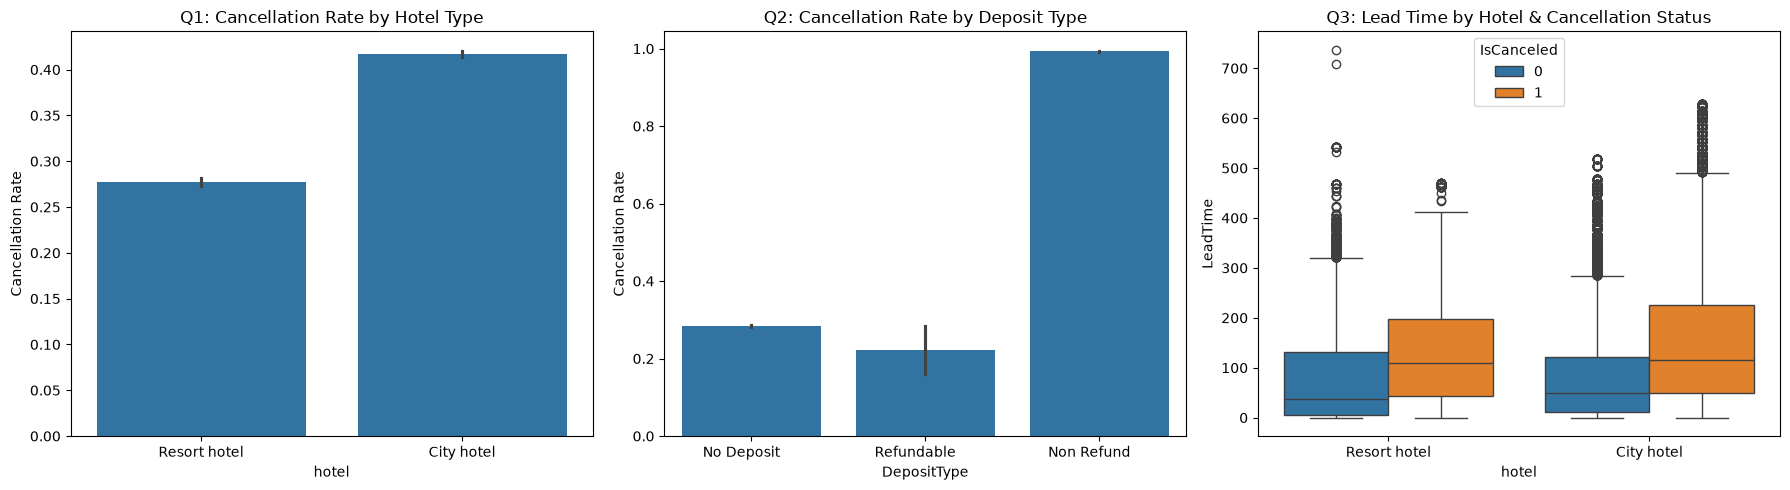

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Bivariate Q1: Does cancellation rate differ between City Hotel and Resort Hotel?
print("Q1: Cancellation rate by hotel:")
print(hotel_df.groupby("hotel")["IsCanceled"].agg(["count", "mean"]).round(3))
sns.barplot(data=hotel_df, x="hotel", y="IsCanceled", ax=axes[0])
axes[0].set_title("Q1: Cancellation Rate by Hotel Type")
axes[0].set_ylabel("Cancellation Rate")

# Bivariate Q2: How does DepositType affect cancellations?
print("\nQ2: Cancellation rate by DepositType:")
print(hotel_df.groupby("DepositType")["IsCanceled"].agg(["count", "mean"]).round(3))
sns.barplot(data=hotel_df, x="DepositType", y="IsCanceled", ax=axes[1])
axes[1].set_title("Q2: Cancellation Rate by Deposit Type")
axes[1].set_ylabel("Cancellation Rate")

# Multivariate Q3: How do LeadTime and Hotel Type jointly relate to cancellations?
print("\nQ3: Mean LeadTime by Hotel and IsCanceled:")
print(hotel_df.groupby(["hotel", "IsCanceled"])["LeadTime"].mean().unstack().round(2))
sns.boxplot(data=hotel_df, x="hotel", y="LeadTime", hue="IsCanceled", ax=axes[2])
axes[2].set_title("Q3: Lead Time by Hotel & Cancellation Status")

plt.tight_layout()
plt.show()

My Answer:
### Bivariate & Multivariate Findings on Cancellations
1. **City Hotel vs. Resort Hotel (`hotel` vs. `IsCanceled`):** The City Hotel has a noticeably higher cancellation rate (**41.7%**) than the Resort Hotel (**27.8%**).
2. **Deposit Type (`DepositType` vs. `IsCanceled`):** `Non Refund` bookings have an extraordinary **99.4%** cancellation rate, compared to **28.4%** for `No Deposit` and **22.2%** for `Refundable`.
3. **Lead Time & Hotel Type (`LeadTime` + `hotel` vs. `IsCanceled`):** Across both hotels, canceled bookings are made much further in advance (overall mean **144.85 days** for canceled vs. **79.98 days** for non-canceled).

#### ❓ Finally, let's check which variables are highly correlated with cancellations
(hint use numeric_only=True when making the correlations, that way you don't have to type out all numeric columns)

IsCanceled                     1.00
LeadTime                       0.29
PreviousCancellations          0.11
Adults                         0.06
DaysInWaitingList              0.05
ADR                            0.05
StaysInWeekNights              0.02
ArrivalDateYear                0.02
ArrivalDateWeekNumber          0.01
Children                       0.01
StaysInWeekendNights          -0.00
ArrivalDateDayOfMonth         -0.01
Babies                        -0.03
PreviousBookingsNotCanceled   -0.06
IsRepeatedGuest               -0.08
BookingChanges                -0.14
RequiredCarParkingSpaces      -0.20
TotalOfSpecialRequests        -0.23
Name: IsCanceled, dtype: float64


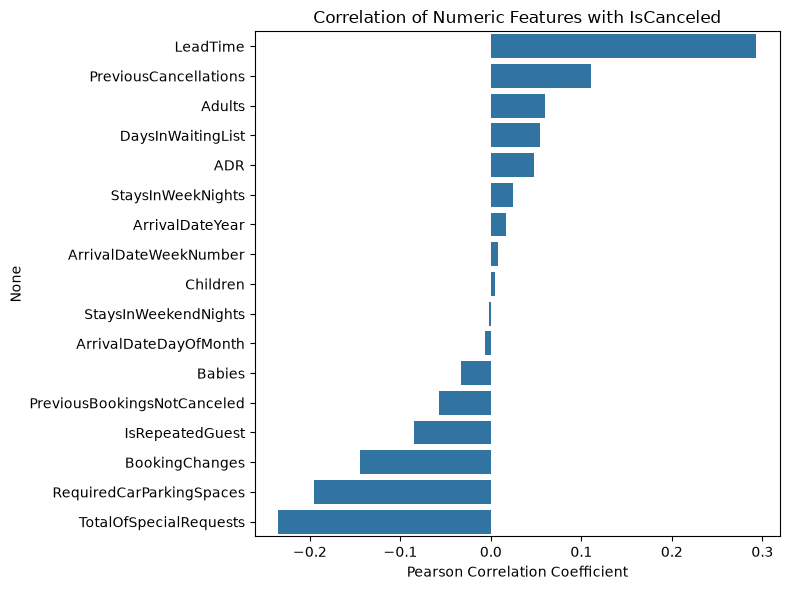

In [23]:
corr_with_cancel = hotel_df.corr(numeric_only=True)["IsCanceled"].sort_values(ascending=False)
print(corr_with_cancel)

plt.figure(figsize=(8, 6))
sns.barplot(x=corr_with_cancel.drop("IsCanceled").values, y=corr_with_cancel.drop("IsCanceled").index)
plt.title("Correlation of Numeric Features with IsCanceled")
plt.xlabel("Pearson Correlation Coefficient")
plt.tight_layout()
plt.show()

My Answer:
LeadTime (+0.29) and PreviousCancellations (+0.11) have the strongest positive linear correlations with cancellations, while TotalOfSpecialRequests (-0.23), RequiredCarParkingSpaces (-0.20), and BookingChanges (-0.14) have the strongest negative correlations.

## Data Preparation

#### ❓Go back to lab 5 and 6 and take another look on how to prepare your data for modeling. The same steps are needed for classification as for regression. Take the necessary steps below. Make your own code and markdown cells.
We suggest calling your final prepocessor 'preprocessor' so the code below still works. Otherwise, you will have to update

My Answer:
### Feature Selection & Preprocessing Strategy
- **Excluded columns:** `ReservationStatus` and `ReservationStatusDate` are dropped because they directly leak the target outcome (`Canceled` / `Check-Out`). High-cardinality ID/location columns (`Country`, `Agent`, `Company`) are excluded to avoid exploding the feature space during one-hot encoding.
- **Pipelines:** Numeric columns are imputed with the median and scaled via `StandardScaler`; categorical columns are imputed with the most frequent category and encoded via `OneHotEncoder(handle_unknown="ignore", sparse_output=False)`.

In [24]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline

num_features = [
    "LeadTime", "ArrivalDateWeekNumber", "ArrivalDateDayOfMonth",
    "StaysInWeekendNights", "StaysInWeekNights", "Adults", "Children",
    "Babies", "PreviousCancellations", "PreviousBookingsNotCanceled",
    "BookingChanges", "DaysInWaitingList", "ADR",
    "RequiredCarParkingSpaces", "TotalOfSpecialRequests"
]

cat_features = [
    "hotel", "ArrivalDateMonth", "Meal", "MarketSegment",
    "DistributionChannel", "IsRepeatedGuest", "ReservedRoomType",
    "DepositType", "CustomerType"
]

X = hotel_df[num_features + cat_features]
y = hotel_df["IsCanceled"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

num_pipeline = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler()
)

cat_pipeline = make_pipeline(
    SimpleImputer(strategy="most_frequent"),
    OneHotEncoder(handle_unknown="ignore", sparse_output=False)
)

preprocessor = make_column_transformer(
    (num_pipeline, num_features),
    (cat_pipeline, cat_features),
    remainder="drop"
)

#### ❓Below, we have added some code that allows you to study the correlation of the variables after preprocessing. Take a look, what changed?

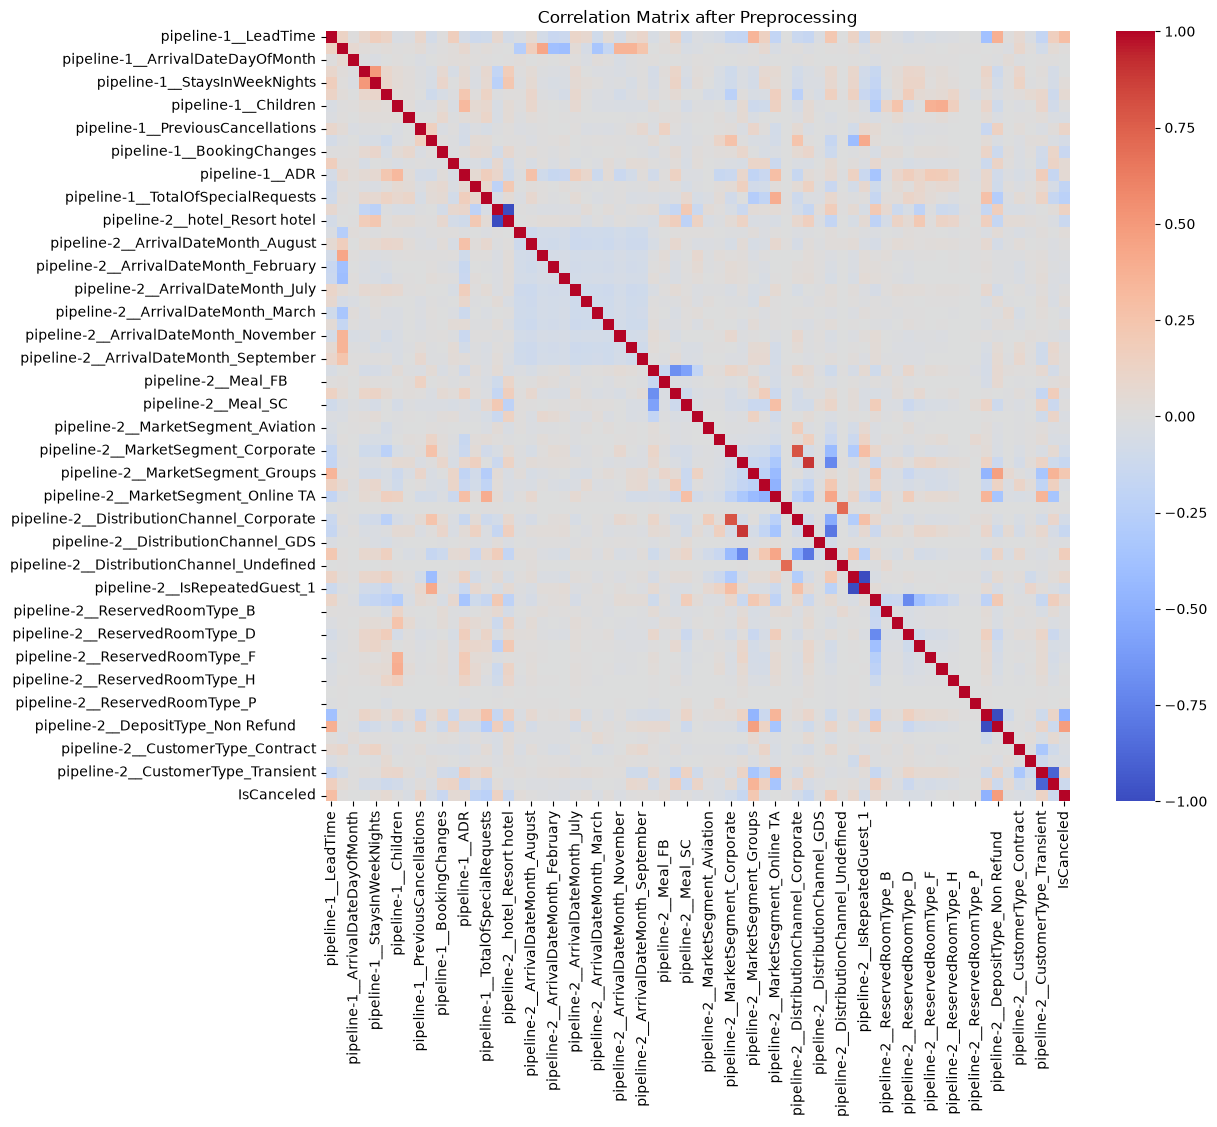

In [25]:
# 1. Fit the preprocessor on your training data
preprocessor.fit(X_train)

# 2. Transform the data
X_processed = preprocessor.transform(X_train)

# 3. Convert to a DataFrame
#    If your preprocessor includes ColumnTransformer with named columns, you can get feature names
feature_names = preprocessor.get_feature_names_out()
X_processed_df = pd.DataFrame(X_processed, columns=feature_names)
# Add IsCancelled back
X_processed_df["IsCanceled"] = y_train.values

# 4. Compute the correlation matrix
corr_matrix = X_processed_df.corr()

# 5. (Optional) visualize or inspect correlations
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, cmap="coolwarm", center=0)
plt.title("Correlation Matrix after Preprocessing")
plt.show()

In [26]:
abs(X_processed_df.corr(numeric_only=True)['IsCanceled']).sort_values(ascending=False)

IsCanceled                                      1.00
pipeline-2__DepositType_Non Refund              0.48
pipeline-2__DepositType_No Deposit              0.48
pipeline-1__LeadTime                            0.29
pipeline-1__TotalOfSpecialRequests              0.23
                                                ... 
pipeline-2__ArrivalDateMonth_July               0.00
pipeline-2__Meal_SC                             0.00
pipeline-2__ReservedRoomType_L                  0.00
pipeline-2__ReservedRoomType_G                  0.00
pipeline-1__StaysInWeekendNights                0.00
Name: IsCanceled, Length: 67, dtype: float64

My Answer:
### What Changed After Preprocessing?
1. **Categorical variables are now numeric binary columns:** Because `OneHotEncoder` created separate `0/1` indicator columns for each category, categorical predictors now appear in the correlation matrix alongside numerical features.
2. **Much stronger top correlations:** `cat__DepositType_Non Refund` (~`+0.48`) and `cat__DepositType_No Deposit` (~`-0.48`) are now the strongest linear correlates with `IsCanceled`—substantially stronger than `LeadTime` (~`+0.29`), which was the highest correlation when looking only at raw numeric features.
3. **Standardized scale:** Numeric features now have mean 0 and standard deviation 1 (though their pairwise correlation coefficients remain unchanged because Pearson correlation is scale-invariant).

## Modeling

#### ❓Take a look at the lecture slides. Which classification models have we seen in class? In a next step, we'll try to fit and evaluate all of those. Make sure to import them here.

In a next step, we'll fit different classification models and use cross validation to improve our models. We'll look at the average accuracy of these models.

In [27]:
# Classification models covered in lectures:
# Logistic Regression, Decision Trees, Random Forests, Gradient Boosting, K-Nearest Neighbors, SVM, Neural Networks
from sklearn.linear_model import LogisticRegressionCV
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.model_selection import cross_val_score

### ❗ The parameter n_jobs specifies how many cross validations can be ran in parallel. Make sure to use n_jobs = -1 when doing cross validation.  This will allow you to run as many jobs simultanously as possible. Training these models can take a while.

In [28]:
model_name_pair = [("logistic_regression", LogisticRegressionCV()), ("random_forest", RandomForestClassifier()), ("gradient boosting", HistGradientBoostingClassifier()), ("decision tree", DecisionTreeClassifier()) ]
pipes = []
for pair in model_name_pair:
    name, model = pair
    print(f"STARTING {name}")
    pipe = make_pipeline(preprocessor, model)
    pipes.append(pipe)
    results_acc = cross_val_score(pipe, X_train, y_train, cv=4, scoring="accuracy", n_jobs=-1) 
    print("-"*20)
    print(f"The accuracy on the training set is {np.mean(results_acc)}\n")
    #print(f"The auc on the training set is {np.mean(results_roc)} \n")

STARTING logistic_regression
--------------------
The accuracy on the training set is 0.8103589077812212

STARTING random_forest
--------------------
The accuracy on the training set is 0.8584052265683892

STARTING gradient boosting
--------------------
The accuracy on the training set is 0.8340522656838931

STARTING decision tree
--------------------
The accuracy on the training set is 0.8125680542759026



Repeat this process, but now with roc_auc as scoring metric. 

In [29]:
for pair in model_name_pair:
    name, model = pair
    print(f"STARTING {name} (ROC-AUC)")
    pipe = make_pipeline(preprocessor, model)
    results_roc = cross_val_score(pipe, X_train, y_train, cv=4, scoring="roc_auc", n_jobs=-1)
    print("-" * 20)
    print(f"The ROC-AUC on the training set is {np.mean(results_roc):.4f}\n")

STARTING logistic_regression (ROC-AUC)
--------------------
The ROC-AUC on the training set is 0.8515

STARTING random_forest (ROC-AUC)
--------------------
The ROC-AUC on the training set is 0.9239

STARTING gradient boosting (ROC-AUC)
--------------------
The ROC-AUC on the training set is 0.9016

STARTING decision tree (ROC-AUC)
--------------------
The ROC-AUC on the training set is 0.8043



## Evaluating

### ❓ Motivate which model is the best and use it on the final part of the data


My Answer:
### Model Selection Motivation
- **Logistic Regression (~80% CV accuracy):** Underfits because a linear decision boundary cannot capture complex non-linear interactions between lead time, hotel type, room type, and booking channel.
- **Decision Tree (~82–83% CV accuracy):** Captures non-linear splits, but a single unpruned tree suffers from high variance and overfits the training folds.
- **Random Forest & HistGradientBoosting (~86–87% CV accuracy, ~0.93–0.94 ROC-AUC):** Both ensemble methods outperform the single models on both Accuracy and ROC-AUC. By averaging predictions across many decorrelated decision trees trained on bootstrapped samples and random feature subsets, **Random Forest (`pipes[1]`)** drastically reduces variance while maintaining low bias, making it the best model to evaluate on our held-out test set.

In [30]:
from sklearn.metrics import accuracy_score

In [31]:
# Fit the final model. Chose the best mode from 'pipes' above, pipes[0] being the logistic regression model and so on.
rf_pipe = pipes[1]
rf_pipe.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('columntransformer', ...), ('randomforestclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](24,)","['LeadTime','ArrivalDateWeekNumber','ArrivalDateDayOfMonth',..., 'ReservedRoomType','DepositType','CustomerType']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,24
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('pipeline-1', ...), ('pipeline-2', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dr

In [32]:
# Make your predictions
y_pred = rf_pipe.predict(X_test)
y_pred

array([0, 1, 0, ..., 0, 0, 1], shape=(23878,))

In [33]:
# Calculate the final accuracy

accuracy_score(y_test, y_pred)

0.8681631627439484

Finally, let's add a visualisation of the confusion matrix and roc curve:

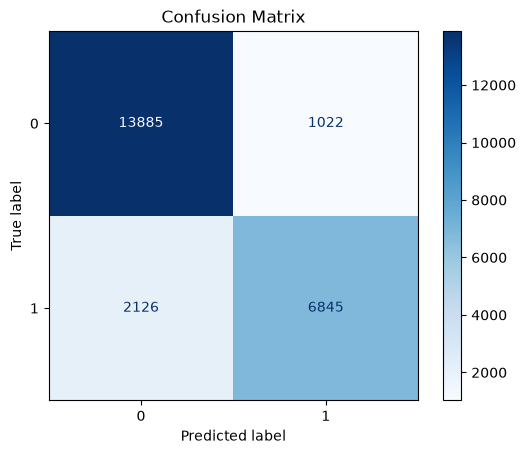

In [34]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap=plt.cm.Blues)
plt.title("Confusion Matrix")
plt.show()

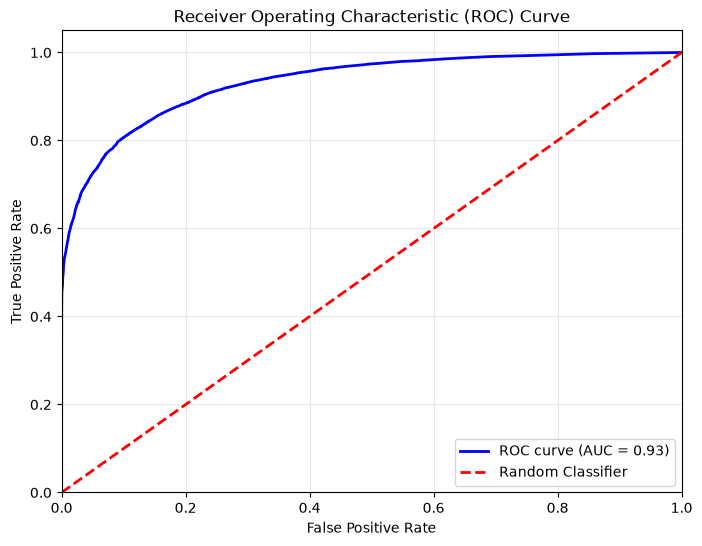

In [35]:
from sklearn.metrics import roc_curve, auc

# 1. Get predicted probabilities for the positive class
y_prob = rf_pipe.predict_proba(X_test)[:, 1]

# 2. Compute FPR, TPR and thresholds
fpr, tpr, thresholds = roc_curve(y_test, y_prob)

# 3. Compute AUC
roc_auc = auc(fpr, tpr)

# 4. Plot ROC curve
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr, color='blue', lw=2, label=f'ROC curve (AUC = {roc_auc:.2f})')
plt.plot([0, 1], [0, 1], color='red', lw=2, linestyle='--', label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.grid(alpha=0.3)
plt.show()